
# Artificial Neural Network for Binary Classification Using the Make Moons Dataset

## 1. Introduction

This project develops an Artificial Neural Network (ANN) to solve a binary classification problem using the `make_moons` dataset from Scikit-learn.

The dataset contains two interleaving, moon-shaped classes. Because the classes form a nonlinear pattern, the project demonstrates how hidden layers and nonlinear activation functions help a neural network learn a complex decision boundary.

## 2. Objectives

- Generate and explore a synthetic binary classification dataset.
- Visualize the distribution of the two classes.
- Split the data into training and testing sets.
- Standardize the input features without leaking information from the test set.
- Build and train a feedforward ANN.
- Evaluate the model using classification metrics.
- Visualize the learned decision boundary.
- Explain the mathematical principles behind neural network training.

## 3. Technologies

- Python
- NumPy and Pandas
- Matplotlib
- Scikit-learn
- TensorFlow / Keras

## 4. Methodology

Dataset Generation → Exploratory Data Analysis → Train/Test Split → Feature Scaling → ANN Construction → Model Training → Evaluation → Decision Boundary Visualization


In [ ]:

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Ensure reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully.")


TensorFlow version: 2.21.0
NumPy version: 2.1.3
Libraries imported successfully.



## 5. Dataset Generation

The `make_moons()` function generates a synthetic dataset containing two interleaving half-circle classes.

Each sample contains two numerical features, `x1` and `x2`, and a binary target label:

- **Class 0:** First moon.
- **Class 1:** Second moon.

The `noise` parameter introduces variation into the sample positions, making the classification problem more realistic than perfectly separated curves.


In [ ]:

# Generate a nonlinear binary classification dataset
X, y = make_moons(
    n_samples=1500,
    noise=0.20,
    random_state=RANDOM_STATE
)

# Create a DataFrame for easier inspection
df = pd.DataFrame(X, columns=["x1", "x2"])
df["target"] = y

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nFeature data type:")
print(df[["x1", "x2"]].dtypes)

print("\nClass distribution:")
print(df["target"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (1500, 3)

First five records:


,x1,x2,target
0,0.998286,-0.499967,1
1,1.835383,0.166852,1
2,0.077737,1.116936,0
3,-0.187394,1.212126,0
4,-0.614158,0.805750,0



Feature data type:
x1    float64
x2    float64
dtype: object

Class distribution:
target
0    750
1    750
Name: count, dtype: int64

Missing values:
x1        0
x2        0
target    0
dtype: int64



## 6. Exploratory Data Analysis

A scatter plot helps reveal the nonlinear relationship between the two input features and the binary target.

This visualization is important because a straight decision boundary may not separate the two moon-shaped classes effectively.


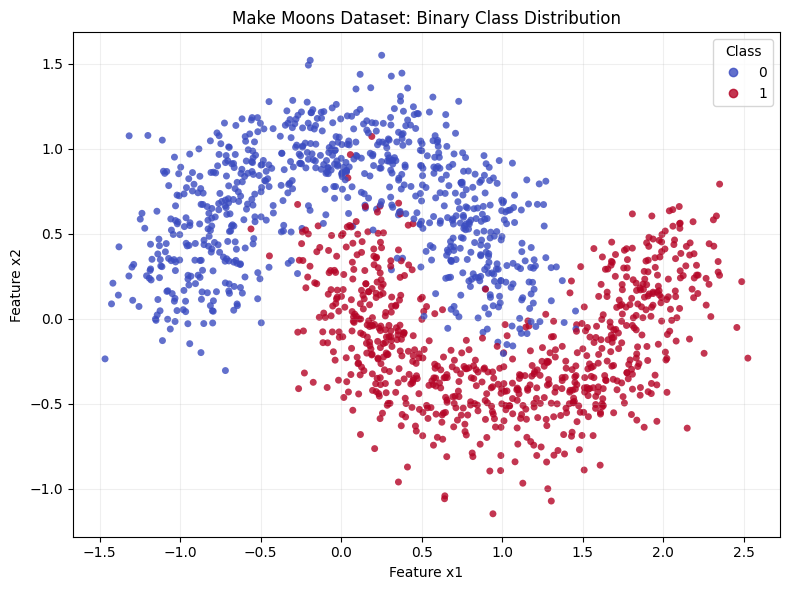

In [ ]:

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["x1"],
    df["x2"],
    c=df["target"],
    cmap="coolwarm",
    s=25,
    alpha=0.8,
    edgecolors="none"
)

plt.title("Make Moons Dataset: Binary Class Distribution")
plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.legend(
    *scatter.legend_elements(),
    title="Class"
)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 7. Train-Test Split and Feature Scaling

The dataset is divided into training and testing subsets.

- **Training set:** Used to learn the model parameters.
- **Testing set:** Used to evaluate performance on unseen data.

An 80:20 split is used. Stratification preserves the proportion of both classes in each subset.

Feature standardization transforms the input features to have approximately zero mean and unit variance. This helps the neural network optimize its weights more effectively.

To prevent data leakage, the scaler is fitted only on the training data. The same transformation is then applied to the test data.

In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Standardize features without leaking test-set information
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display dataset dimensions
print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])

print("\nTraining feature means:")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 4))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 1200
Testing samples: 300

Training feature means:
[-0.  0.]

Training feature standard deviations:
[1. 1.]

Training class distribution:
0    600
1    600
Name: count, dtype: int64

Testing class distribution:
0    150
1    150
Name: count, dtype: int64


## 8. Artificial Neural Network Architecture

A feedforward Artificial Neural Network (ANN) is constructed using TensorFlow and Keras.

The network contains:

1. **Input layer:** Accepts the two standardized numerical features.
2. **First hidden layer:** Contains 16 neurons with ReLU activation.
3. **Second hidden layer:** Contains 8 neurons with ReLU activation.
4. **Output layer:** Contains one neuron with sigmoid activation to predict the probability of Class 1.

### Activation Functions

The ReLU activation function is defined as:

\[
\operatorname{ReLU}(z)=\max(0,z)
\]

ReLU introduces nonlinearity, allowing the network to learn curved decision boundaries.

The sigmoid function is:

\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

It converts the output into a probability between 0 and 1. A probability of at least 0.5 is classified as Class 1; otherwise, it is classified as Class 0.

### Model Compilation

The network uses the Adam optimizer and binary cross-entropy loss. Binary cross-entropy measures the difference between predicted probabilities and the true binary labels.

In [ ]:
# Build the feedforward Artificial Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(16, activation="relu", name="hidden_layer_1"),
    tf.keras.layers.Dense(8, activation="relu", name="hidden_layer_2"),
    tf.keras.layers.Dense(1, activation="sigmoid", name="output_layer")
])

# Configure the training process
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

## 9. Model Training

The ANN is trained using the standardized training data over multiple epochs.

An epoch represents one complete pass through the training dataset. During training, the Adam optimizer updates the network weights to minimize binary cross-entropy loss.

A portion of the training data is used for validation to monitor performance on data not used for weight updates. The test set remains untouched until final evaluation.

In [ ]:
# Train the ANN
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    shuffle=True,
    verbose=1
)

print("\nModel training completed.")

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7094 - loss: 0.6478 - val_accuracy: 0.7708 - val_loss: 0.5967
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7719 - loss: 0.5747 - val_accuracy: 0.8500 - val_loss: 0.5269
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8260 - loss: 0.5014 - val_accuracy: 0.8667 - val_loss: 0.4559
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8552 - loss: 0.4306 - val_accuracy: 0.8750 - val_loss: 0.3950
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8729 - loss: 0.3743 - val_accuracy: 0.8667 - val_loss: 0.3521
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8771 - loss: 0.3364 - val_accuracy: 0.8667 - val_loss: 0.3257
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8802 - loss: 0.3132 - val_accuracy: 0.8750 - val_loss: 0.3094
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8823 - loss: 0.2990 - val_accuracy: 0.8750 -

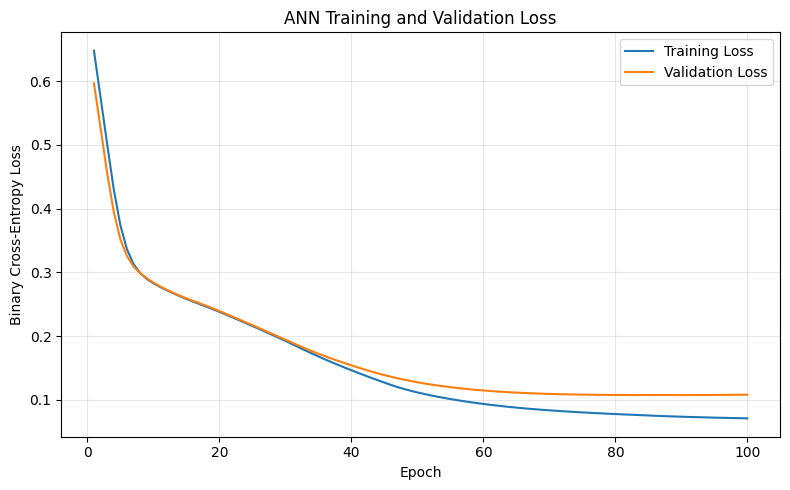

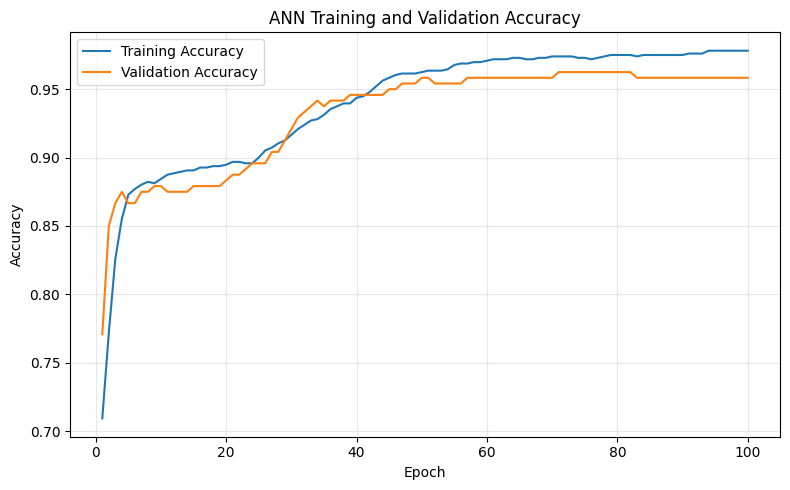

In [ ]:
# Extract training history
epochs_range = range(1, len(history.history["loss"]) + 1)

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["loss"], label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation Loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Model Evaluation

The trained ANN is evaluated using the test dataset, which was not used during training or validation.

The following metrics are calculated:

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Proportion of predicted positive cases that are actually positive.
- **Recall:** Proportion of actual positive cases correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures how well the model distinguishes between the two classes across classification thresholds.
- **Confusion matrix:** Summarizes correct and incorrect predictions for each class.

ANN TEST SET PERFORMANCE
Accuracy : 0.9600 (96.00%)
Precision: 0.9600
Recall   : 0.9600
F1-score : 0.9600
ROC-AUC  : 0.9940

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.96      0.96      0.96       150
     Class 1       0.96      0.96      0.96       150

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300



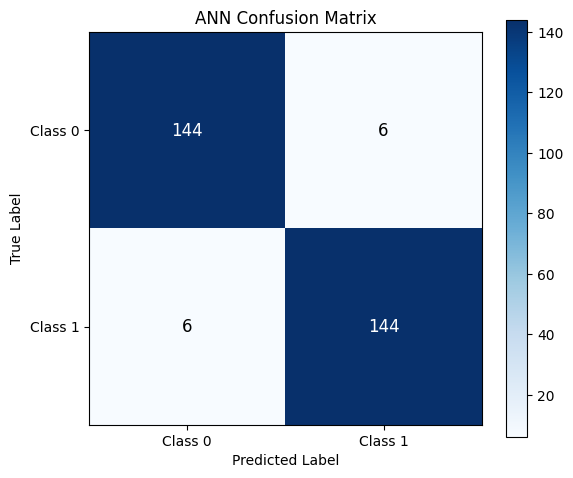

In [ ]:
# Predict probabilities for the unseen test set
y_test_prob = model.predict(X_test_scaled, verbose=0).ravel()

# Convert probabilities into binary predictions
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_roc_auc = roc_auc_score(y_test, y_test_prob)

print("ANN TEST SET PERFORMANCE")
print("=" * 35)
print(f"Accuracy : {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Class 0", "Class 1"],
        zero_division=0
    )
)

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("ANN Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.yticks([0, 1], ["Class 0", "Class 1"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

threshold = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=12
        )

plt.tight_layout()
plt.show()

## 11. Decision Boundary Visualization

A decision boundary separates regions of the feature space assigned to different classes.

The ANN predicts a probability for each point on a two-dimensional grid. These probabilities are visualized as a contour map, with the 0.5 probability contour representing the classification boundary.

The resulting visualization helps demonstrate how a neural network with nonlinear hidden layers can learn a curved decision boundary for the make-moons dataset.

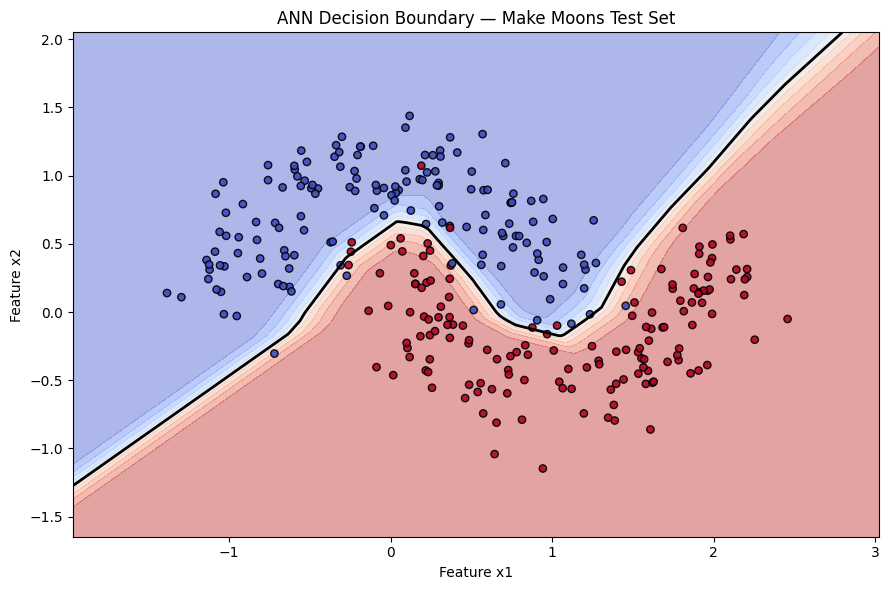

In [ ]:
# Define a grid covering the feature space
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Scale grid points using the scaler fitted on training data
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_points_scaled = scaler.transform(grid_points)

# Predict Class 1 probabilities across the grid
grid_probabilities = model.predict(
    grid_points_scaled,
    verbose=0
).reshape(xx.shape)

# Plot the probability regions and decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(
    xx,
    yy,
    grid_probabilities,
    levels=np.linspace(0, 1, 11),
    cmap="coolwarm",
    alpha=0.45
)

plt.contour(
    xx,
    yy,
    grid_probabilities,
    levels=[0.5],
    colors="black",
    linewidths=2
)

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=28,
    alpha=0.9
)

plt.title("ANN Decision Boundary — Make Moons Test Set")
plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.tight_layout()
plt.show()

## 12. Results and Discussion

The model was evaluated on 300 test samples that were not used for training or validation.

| Metric | Result |
|---|---:|
| Accuracy | 96.00% |
| Precision | 0.9600 |
| Recall | 0.9600 |
| F1-score | 0.9600 |
| ROC-AUC | 0.9940 |

The model correctly classified 96% of the test samples. Precision and recall were also 96%, indicating balanced performance on the two classes. The ROC-AUC of 0.9940 indicates that the model distinguished between the classes well across different classification thresholds.

The decision-boundary plot illustrates how the network learned a nonlinear boundary that follows the structure of the two moon-shaped classes.

These results apply to this synthetic dataset and do not guarantee similar performance on real-world data.

## 13. Limitations and Future Improvements

### Limitations

1. **Synthetic dataset:** The make-moons dataset is artificially generated and may not represent the complexity of real-world classification problems.
2. **Hyperparameter dependence:** Performance depends on the network architecture, learning rate, batch size, and number of epochs.
3. **Random initialization:** Different initial weights or random seeds may produce different results.
4. **Limited model comparison:** This experiment focuses on one ANN architecture and does not establish that it is superior to all alternative classifiers.
5. **Generalization scope:** Performance on this dataset does not establish how well the model will perform on unrelated datasets.

### Future Improvements

- Compare the ANN against Logistic Regression, a Decision Tree, and an SVM.
- Experiment with different hidden-layer sizes and activation functions.
- Investigate early stopping and regularization to control overfitting.
- Evaluate performance across multiple random seeds.

## 14. Conclusion

This project uses an Artificial Neural Network (ANN) to classify data generated by the Make Moons dataset. The model learned a nonlinear decision boundary and achieved 96% test accuracy with a 0.9940 ROC-AUC score.

The results demonstrate how a neural network can learn complex patterns that a simple linear classifier may struggle to represent. However, performance on synthetic data does not guarantee the same results on real-world datasets.

Possible Improvements

Experiment with different network architectures and hidden-layer sizes.

Compare activation functions and learning rates.

Plot training and validation loss to study convergence and overfitting.

Compare the ANN with models such as Logistic Regression and SVM.